# Predikcija hronične bolesti bubrega primenom mašinskog učenja

## Veštačka inteligencija

 Alempijević Neda 2021/203673

# 1. Definicija problema

Hronična bolest bubrega (Chronic Kidney Disease – CKD) je jedno od ozbiljnijih oboljenja koje može dugo da se razvija bez izraženih simptoma. Zbog toga je rano otkrivanje bolesti veoma važno, jer može pomoći da se na vreme započne lečenje i spreči dalje oštećenje bubrega.

U poslednjih nekoliko godina mašinsko učenje sve više pronalazi primenu u medicini. Analizom podataka moguće je uočiti obrasce koje nije uvek lako prepoznati, što može biti korisno kao dodatna podrška lekarima prilikom procene zdravstvenog stanja pacijenata.

U ovom projektu razvijen je model koji na osnovu medicinskih podataka predviđa da li pacijent ima hroničnu bolest bubrega. Projekat obuhvata analizu i pripremu skupa podataka, primenu više algoritama mašinskog učenja i poređenje njihovih rezultata kako bi se utvrdilo koji model daje najbolje performanse.

Važno je naglasiti da cilj ovog projekta nije postavljanje medicinske dijagnoze, već ispitivanje mogućnosti primene mašinskog učenja za klasifikaciju pacijenata na osnovu dostupnih podataka.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# 2. Učitavanje skupa podataka

Prvi korak u projektu bio je učitavanje skupa podataka u Python pomoću biblioteke Pandas. Nakon učitavanja prikazani su prvi redovi tabele kako bi se proverilo da li su podaci ispravno učitani i kako bi se stekao uvid u nazive kolona i sadržaj skupa podataka.

Za ovaj projekat korišćen je javno dostupan skup podataka koji sadrži informacije o pacijentima i njihovim medicinskim parametrima. Dataset obuhvata 400 pacijenata i 25 atributa, koji opisuju različite karakteristike važne za predviđanje hronične bolesti bubrega.

Skup podataka sadrži i numeričke i kategoričke atribute. Ciljna promenljiva predstavlja informaciju o tome da li pacijent ima ili nema hroničnu bolest bubrega i upravo nju modeli pokušavaju da predvide.

In [2]:
df = pd.read_csv("kidney_disease.csv")

df.head()

,id,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35,7300,4.6,no,no,no,good,no,no,ckd


In [3]:
if "id" in df.columns:
    df = df.drop("id", axis=1)

df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38,6000,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35,7300,4.6,no,no,no,good,no,no,ckd


 Kolona id nije korišćena u daljoj analizi jer predstavlja samo jedinstveni identifikator pacijenta. Pošto ne sadrži informacije koje su povezane sa bolešću, ne doprinosi treniranju modela i može negativno uticati na proces učenja.


# 3. Analiza podataka

## 3.1 Analiza strukture podataka

Nakon učitavanja skupa podataka analizirala sam njegovu strukturu kako bih stekla uvid u broj instanci, broj atributa i tipove podataka koje dataset sadrži.

Ovaj korak je bio važan jer mi je pomogao da utvrdim koji su atributi numerički, a koji kategorički, kako bih mogla da ih na odgovarajući način pripremim za dalje korake u projektu.

In [4]:
df.shape

(400, 25)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             391 non-null    float64
 1   bp              388 non-null    float64
 2   sg              353 non-null    float64
 3   al              354 non-null    float64
 4   su              351 non-null    float64
 5   rbc             248 non-null    str    
 6   pc              335 non-null    str    
 7   pcc             396 non-null    str    
 8   ba              396 non-null    str    
 9   bgr             356 non-null    float64
 10  bu              381 non-null    float64
 11  sc              383 non-null    float64
 12  sod             313 non-null    float64
 13  pot             312 non-null    float64
 14  hemo            348 non-null    float64
 15  pcv             330 non-null    str    
 16  wc              295 non-null    str    
 17  rc              270 non-null    str    
 18  h

## 3.2 Analiza nedostajućih vrednosti

Nakon analize strukture podataka proverila sam da li u datasetu postoje nedostajuće vrednosti i u kojim kolonama se one pojavljuju. Ovakvi podaci su česti u realnim skupovima podataka i potrebno ih je obraditi pre treniranja modela, jer mogu uticati na njegove performanse.

Cilj ove analize bio je da utvrdim koje kolone sadrže nedostajuće vrednosti i da odaberem odgovarajući način njihovog popunjavanja kako bi podaci bili spremni za dalju obradu.

In [6]:
df.isnull().sum()

age                 9
bp                 12
sg                 47
al                 46
su                 49
rbc               152
pc                 65
pcc                 4
ba                  4
bgr                44
bu                 19
sc                 17
sod                87
pot                88
hemo               52
pcv                70
wc                105
rc                130
htn                 2
dm                  2
cad                 2
appet               1
pe                  1
ane                 1
classification      0
dtype: int64

Rezultati pokazuju da pojedine kolone imaju veći broj nedostajućih vrednosti, naročito one koje se odnose na laboratorijske parametre pacijenata.

Zbog toga sam u narednom koraku popunila nedostajuće vrednosti odgovarajućim statističkim pokazateljima, kako bi podaci bili spremni za dalju obradu i treniranje modela.

## 3.3 Vizualizacija podataka

Nakon analize podataka prikazala sam najvažnije karakteristike skupa podataka pomoću grafikona. Na ovaj način bilo je lakše uočiti raspodelu klasa, odnose između pojedinih atributa i obrasce koji mogu biti značajni za dalju analizu.

Vizualizacija podataka pomogla mi je da bolje razumem dataset pre primene modela mašinskog učenja i da steknem jasniju sliku o podacima sa kojima radim.

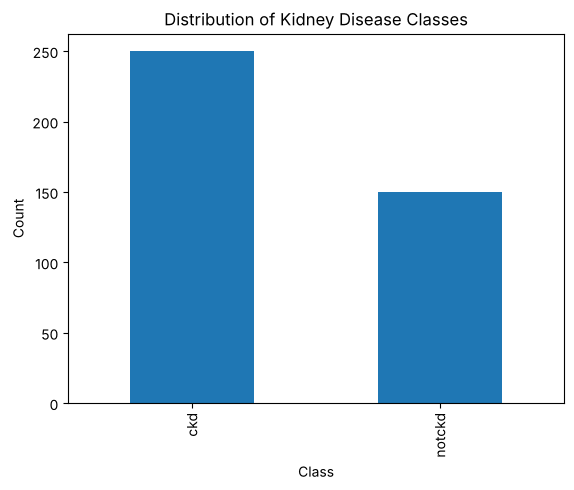

In [7]:
df["classification"].str.strip().value_counts().plot(kind="bar")

plt.title("Distribution of Kidney Disease Classes")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

### Tumačenje grafikona 1

Na osnovu grafikona može se videti da je broj pacijenata sa hroničnom bolešću bubrega nešto veći u odnosu na broj pacijenata bez bolesti.

Iako klase nisu potpuno izbalansirane, razlika između njih nije velika, pa nije bilo potrebe za dodatnim metodama balansiranja podataka pre treniranja modela.

### Grafikon 2 – Raspodela starosti pacijenata

Kako bih stekla bolji uvid u starosnu strukturu pacijenata, prikazala sam raspodelu njihovih godina pomoću histograma. Na osnovu njega može se videti koliko su pojedine starosne grupe zastupljene u skupu podataka.



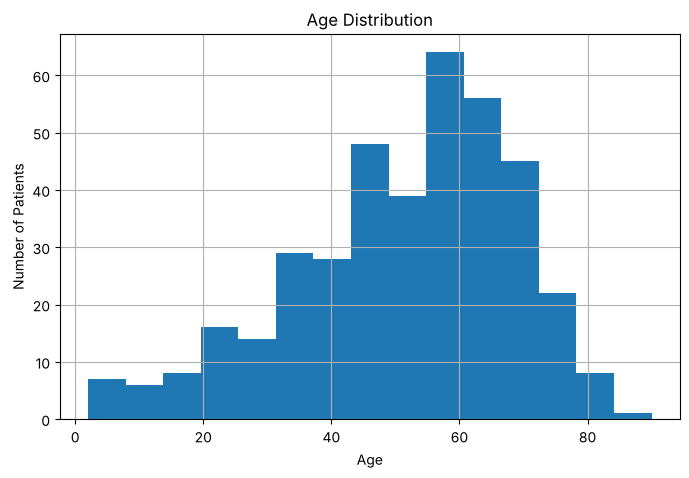

In [8]:
plt.figure(figsize=(8,5))

df["age"].hist(bins=15)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

### Tumačenje grafikona 2

Na osnovu prikazanog histograma može se primetiti da najveći broj pacijenata u ovom skupu podataka pripada srednjoj i starijoj životnoj dobi, dok je najmanje ispitanika u najmlađim i najstarijim starosnim grupama.


### Grafikon 3 – Nedostajuće vrednosti po atributima

Pre treniranja modela proverila sam broj nedostajućih vrednosti u svakoj koloni. Ovaj korak bio je važan kako bih utvrdila koji atributi zahtevaju dodatnu obradu pre primene algoritama mašinskog učenja.


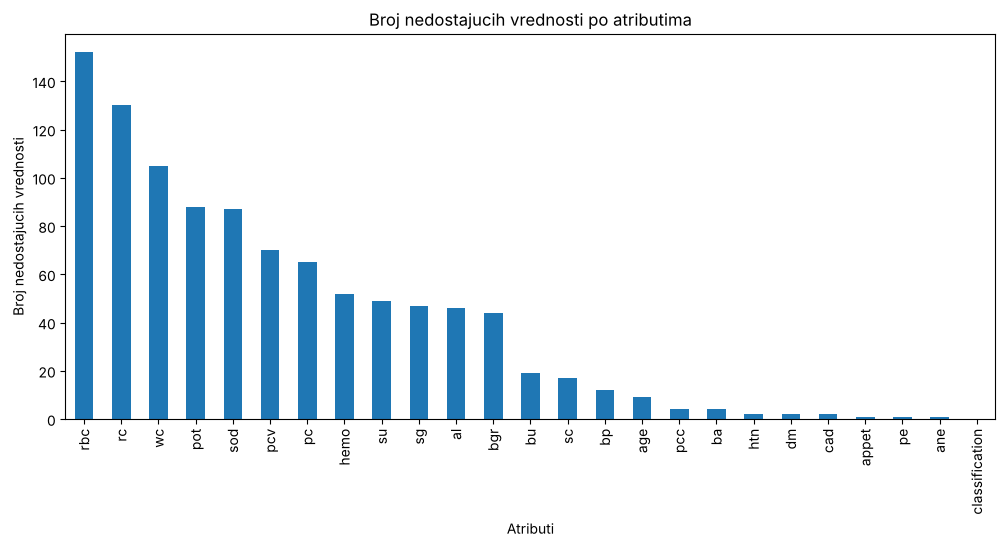

In [9]:
plt.figure(figsize=(12,5))

df.isnull().sum().sort_values(ascending=False).plot(kind="bar")

plt.title("Broj nedostajucih vrednosti po atributima")
plt.xlabel("Atributi")
plt.ylabel("Broj nedostajucih vrednosti")

plt.show()

### Tumačenje grafikona 3

Na osnovu grafikona uočila sam da pojedini atributi sadrže veliki broj nedostajućih vrednosti. Najviše ih ima u atributu rbc, dok značajan broj nedostajućih vrednosti imaju i rc i wc.

Na osnovu ovih rezultata zaključila sam da je pre treniranja modela neophodno obraditi nedostajuće vrednosti kako bi skup podataka bio kompletan i pogodan za dalju analizu.

# 4. Predobrada podataka

Pre nego što sam krenula sa treniranjem modela, bilo je potrebno pripremiti podatke. To je podrazumevalo čišćenje tekstualnih vrednosti, ispravljanje tipova podataka, popunjavanje nedostajućih vrednosti i pretvaranje kategoričkih atributa u numerički oblik.

Na taj način dobijen je skup podataka koji je spreman za primenu algoritama mašinskog učenja i dalju analizu.

## 4.1 Čišćenje tekstualnih vrednosti

Pre treniranja modela proverila sam ciljnu promenljivu classification, koja označava da li pacijent ima hroničnu bolest bubrega ili ne. Primetila sam da se u pojedinim zapisima nalaze suvišni razmaci i tabulatori, zbog čega iste kategorije mogu biti različito prepoznate.

Isti problem postoji i u drugim kategoričkim kolonama. Na primer, kolona dm (dijabetes) sadrži vrednosti „yes“, „ yes“ i „\tyes“, koje model bez čišćenja vidi kao tri različite kategorije. Zato sam suvišne razmake uklonila iz svih tekstualnih kolona, a ne samo iz ciljne promenljive.

In [10]:
print(df["classification"].value_counts(), "\n")
print(df["dm"].value_counts())

classification
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64 

dm
no       258
yes      134
\tno       3
\tyes      2
 yes       1
Name: count, dtype: int64


In [11]:
text_cols = df.select_dtypes(exclude="number").columns

for col in text_cols:
    df[col] = df[col].str.strip()

print(df["classification"].value_counts(), "\n")
print(df["dm"].value_counts())

classification
ckd       250
notckd    150
Name: count, dtype: int64 

dm
no     261
yes    137
Name: count, dtype: int64


### Rezultat čišćenja tekstualnih vrednosti

Nakon uklanjanja suvišnih razmaka u ciljnoj promenljivoj ostale su dve jasno definisane klase: „ckd“ i „notckd“. Kolona dm sada takođe ima samo dve vrednosti, „yes“ i „no“, kao i ostale kategoričke kolone.

Na taj način sve vrednosti su zapisane na isti način, pa model neće pogrešno tretirati iste kategorije kao različite.

## 4.2 Ispravljanje tipova numeričkih kolona

Prilikom analize strukture podataka uočila sam da su kolone pcv (hematokrit), wc (broj leukocita) i rc (broj eritrocita) učitane kao tekst, iako predstavljaju numeričke laboratorijske vrednosti. Razlog je to što pojedina polja u ovim kolonama sadrže znak „?“ umesto broja.

Ako bi ove kolone ostale tekstualne, kasnije bi bile kodirane kao kategorije, pa bi model izgubio informaciju o tome da je, na primer, 7800 leukocita više od 6000. Zato sam ih pretvorila u brojeve, a neispravne zapise označila kao nedostajuće vrednosti, koje se popunjavaju u narednom koraku.

In [12]:
numeric_text_cols = ["pcv", "wc", "rc"]

print(df["wc"].dropna()[~df["wc"].dropna().str.isnumeric()].unique())

for col in numeric_text_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[numeric_text_cols].dtypes

<StringArray>
['?']
Length: 1, dtype: str


pcv    float64
wc     float64
rc     float64
dtype: object

## 4.3 Korelaciona matrica

Nakon ispravljanja tipova podataka analizirala sam međusobnu povezanost numeričkih atributa pomoću korelacione matrice. Sada su u nju uključene i kolone pcv, wc i rc. Na osnovu nje može se videti da li između pojedinih atributa postoji pozitivna ili negativna korelacija.


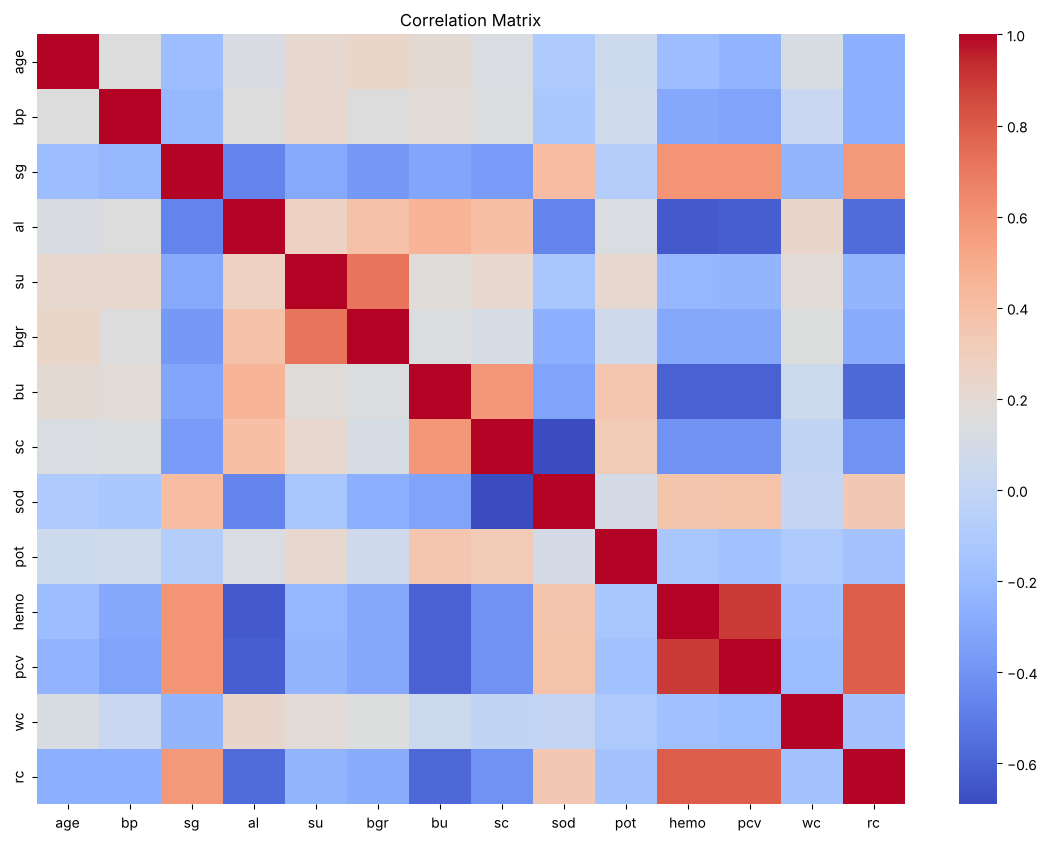

In [13]:
plt.figure(figsize=(14,10))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Matrix")
plt.show()

### Tumačenje grafikona 4

Korelaciona matrica prikazuje međusobnu povezanost numeričkih atributa u skupu podataka. Crvene nijanse označavaju pozitivnu korelaciju, dok plave nijanse predstavljaju negativnu korelaciju između atributa.

Na osnovu grafikona može se uočiti da pojedini atributi pokazuju jaču međusobnu povezanost, dok između drugih ne postoji značajnija korelacija. Na primer, hemoglobin (hemo), hematokrit (pcv) i broj eritrocita (rc) međusobno su pozitivno povezani, što je očekivano jer svi opisuju stanje crvenih krvnih zrnaca. Ovakva analiza pruža bolji uvid u odnose između atributa i pomaže u razumevanju strukture podataka.


## 4.4 Obrada nedostajućih vrednosti

U skupu podataka pronašla sam nedostajuće vrednosti koje je bilo potrebno popuniti pre treniranja modela. Za numeričke atribute koristila sam medijanu, dok sam za kategoričke atribute primenila modu, odnosno najčešće zastupljenu vrednost.

Na ovaj način zadržani su svi podaci, a dataset je pripremljen za dalje korake u procesu mašinskog učenja.


In [14]:
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(exclude="number").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print(df.isnull().sum().sum())

0


Nakon obrade nedostajućih vrednosti izvršila sam proveru skupa podataka. Rezultat pokazuje da više nema nedostajućih vrednosti, čime je obezbeđena potpuna spremnost podataka za treniranje modela mašinskog učenja.

## 4.5 Kodiranje kategoričkih atributa

Pošto algoritmi mašinskog učenja ne mogu direktno da rade sa tekstualnim podacima, kategoričke atribute pretvorila sam u numeričke pomoću metode LabelEncoder.

Na ovaj način svaka tekstualna vrednost zamenjena je odgovarajućim brojem, tako da modeli mogu da koriste ove podatke tokom treniranja.

Nakon kodiranja prikazala sam prvih nekoliko redova skupa podataka kako bih proverila da li su sve vrednosti ispravno transformisane.


In [15]:
le = LabelEncoder()

for col in df.select_dtypes(exclude="number").columns:
    df[col] = le.fit_transform(df[col])

df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,36.0,1.2,138.0,4.4,15.4,44.0,7800.0,5.2,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,18.0,0.8,138.0,4.4,11.3,38.0,6000.0,4.8,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,53.0,1.8,138.0,4.4,9.6,31.0,7500.0,4.8,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,56.0,3.8,111.0,2.5,11.2,32.0,6700.0,3.9,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,26.0,1.4,138.0,4.4,11.6,35.0,7300.0,4.6,0,0,0,0,0,0,0


### Rezultat kodiranja atributa

Prikazani podaci potvrđuju da su svi kategorički atributi uspešno transformisani u numerički oblik, dok su kolone pcv, wc i rc zadržale svoje stvarne numeričke vrednosti.

Ciljna promenljiva kodirana je tako da vrednost 0 označava pacijente sa hroničnom bolešću bubrega (ckd), a vrednost 1 pacijente bez bolesti (notckd).

Time je obezbeđena kompatibilnost podataka sa algoritmima mašinskog učenja i omogućena dalja obrada, podela skupa podataka i treniranje modela za predikciju hronične bolesti bubrega.

# 5. Podela skupa podataka

Pre treniranja modela podelila sam skup podataka na trening i test skup. Trening skup korišćen je za učenje modela, dok je test skup poslužio za proveru njegove uspešnosti na podacima koje prethodno nije video.

Za ovaj projekat izdvojeno je 80% podataka za treniranje, dok je preostalih 20% iskorišćeno za testiranje. Ovakva podela omogućava realniju procenu uspešnosti modela na novim podacima.


In [16]:
X = df.drop("classification", axis=1)
y = df["classification"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(320, 24)
(80, 24)


### Rezultat podele podataka

Nakon podele skupa podataka dobijeno je 320 instanci za treniranje modela i 80 instanci za testiranje.

Broj atributa ostao je isti i iznosi 24, što znači da je jedina razlika između trening i test skupa broj instanci koje sadrže.


# 6. Treniranje i evaluacija modela

## 6.1 Logistička regresija

Logistička regresija je jedan od osnovnih algoritama za klasifikaciju. Na osnovu vrednosti atributa procenjuje verovatnoću da pacijent pripada određenoj klasi, pa je pogodna kao polazni model sa kojim se mogu porediti složeniji algoritmi.

In [17]:
lr = LogisticRegression(max_iter=10000)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

Accuracy: 0.975


### Rezultati logističke regresije

Model logističke regresije ostvario je tačnost od **97,5%** na test skupu podataka.

Dobijeni rezultat pokazuje da model veoma uspešno razlikuje pacijente sa hroničnom bolešću bubrega od pacijenata koji nemaju ovu bolest. Visoka tačnost ukazuje da je logistička regresija dala veoma dobre rezultate na ovom skupu podataka.


## 6.2 K najbližih suseda (KNN)

KNN (K-Nearest Neighbors) je algoritam klasifikacije koji novu instancu svrstava u klasu na osnovu njenih najbližih suseda.

U ovom projektu koristila sam vrednost **k = 5**, što znači da model prilikom klasifikacije uzima u obzir pet najbližih instanci iz trening skupa.

Pošto KNN odluku donosi na osnovu udaljenosti između instanci, veoma je osetljiv na razlike u opsezima atributa. Kolona wc ima vrednosti reda veličine nekoliko hiljada, dok većina ostalih atributa ima vrednosti do nekoliko desetina. Zbog toga sam model trenirala dva puta: prvo bez skaliranja, a zatim uz standardizaciju atributa pomoću StandardScaler-a, kako bih uporedila rezultate.

In [18]:
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
print("Accuracy bez skaliranja:", accuracy_score(y_test, knn_raw.predict(X_test)))

knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
print("Accuracy sa skaliranjem:", accuracy_score(y_test, y_pred_knn))

Accuracy bez skaliranja: 0.6875
Accuracy sa skaliranjem: 0.975


### Rezultati KNN modela

Bez skaliranja atributa KNN model ostvario je tačnost od 68,75% na test skupu podataka, što je znatno lošije od logističke regresije. Razlog je to što atribut wc, zbog velikih vrednosti, gotovo u potpunosti određuje udaljenost između pacijenata, pa ostali atributi skoro da nemaju uticaj na odluku modela.

Nakon standardizacije atributa, kada svi atributi imaju sličan opseg vrednosti, tačnost KNN modela porasla je na 97,5%. Ovaj rezultat pokazuje koliko je priprema podataka važna kod algoritama koji se zasnivaju na udaljenosti, i da na uspešnost modela, pored izbora parametra k, značajno utiče i način na koji su podaci pripremljeni.

## 6.3 Random Forest

Random Forest je ansambl algoritam koji koristi više stabala odlučivanja kako bi doneo konačnu odluku prilikom klasifikacije.

Jedna od njegovih prednosti je što kombinovanjem većeg broja stabala često postiže veću tačnost i stabilnije rezultate u odnosu na pojedinačno stablo odlučivanja.

U ovom projektu korišćeno je 100 stabala odlučivanja.


In [19]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

Accuracy: 1.0


### Rezultati Random Forest modela

Random Forest model ostvario je tačnost od 100% na test skupu podataka.

U poređenju sa ostalim testiranim modelima, Random Forest ostvario je najbolje rezultate i uspešno klasifikovao sve instance iz test skupa.

Na osnovu dobijenih rezultata može se zaključiti da je Random Forest dao najbolje performanse na korišćenom skupu podataka.


## Grafikon 5 – Poređenje tačnosti modela

Kako bih uporedila uspešnost primenjenih modela, prikazala sam njihovu tačnost na test skupu podataka.

Na grafikonu su prikazani rezultati modela Logistic Regression, KNN i Random Forest, što omogućava jednostavno poređenje njihovih performansi.


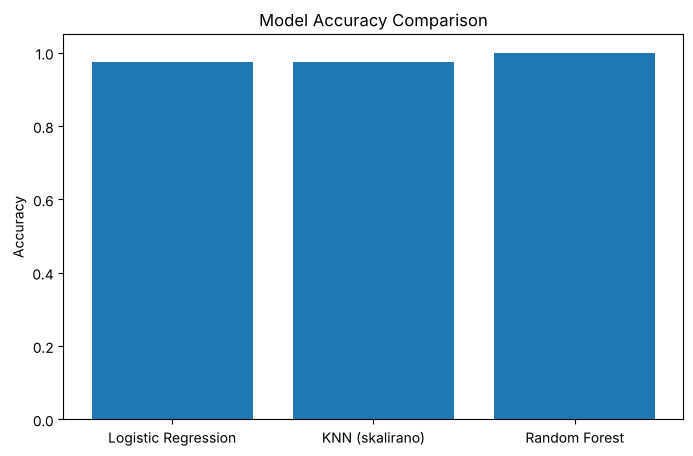

In [20]:
models = ["Logistic Regression", "KNN (skalirano)", "Random Forest"]
scores_test = [
    accuracy_score(y_test, y_pred_lr),
    accuracy_score(y_test, y_pred_knn),
    accuracy_score(y_test, y_pred_rf),
]

plt.figure(figsize=(8,5))

plt.bar(models, scores_test)

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

plt.show()

### Tumačenje grafikona 5

Grafikon pokazuje da je Random Forest ostvario najbolju tačnost od 100%. Logistička regresija i KNN model sa skaliranim atributima ostvarili su jednaku tačnost od 97,5%.

Razlike između modela su male, ali se Random Forest izdvojio kao najuspešniji model za klasifikaciju pacijenata u ovom projektu. Pošto test skup sadrži samo 80 pacijenata, jedna pogrešna klasifikacija menja tačnost za 1,25%, pa je zbog toga u nastavku urađena i unakrsna validacija.

In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_rf)
print(cm)

[[52  0]
 [ 0 28]]


## Grafikon 6 – Matrica konfuzije Random Forest modela

Pored tačnosti, analizirala sam i matricu konfuzije kako bih detaljnije procenila uspešnost Random Forest modela.

Matrica konfuzije prikazuje koliko je instanci model ispravno, a koliko pogrešno klasifikovao za svaku klasu.


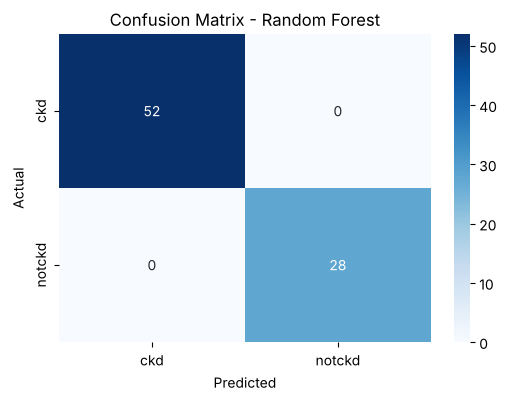

In [22]:
plt.figure(figsize=(6,4))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=["ckd", "notckd"],
            yticklabels=["ckd", "notckd"])

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### Tumačenje grafikona 6

Matrica konfuzije pokazuje da je Random Forest model ispravno klasifikovao svih 80 instanci iz test skupa.

Model je tačno prepoznao 52 pacijenta sa hroničnom bolešću bubrega (ckd) i 28 pacijenata bez ove bolesti (notckd), bez ijedne pogrešne klasifikacije. Zbog toga nema ni lažno pozitivnih ni lažno negativnih predikcija.

Ovakav rezultat potvrđuje da je Random Forest ostvario veoma dobre performanse na ovom skupu podataka, ali ga treba tumačiti uz oprez, jer je test skup relativno mali.

## Grafikon 7 – Cross Validation analiza

Pored testiranja na test skupu, proverila sam stabilnost Random Forest modela i primenom 5-fold Cross Validation metode.

Tom prilikom skup podataka podeljen je na pet delova, pri čemu je model više puta treniran i testiran na različitim kombinacijama podataka.

Na ovaj način dobija se realnija slika o tome koliko model može uspešno da radi i na podacima koje ranije nije video.


In [23]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X,
    y,
    cv=5
)

print("Cross Validation Scores:", scores)
print("Average Accuracy:", scores.mean())

Cross Validation Scores: [0.9875 1.     0.9625 0.9875 1.    ]
Average Accuracy: 0.9875


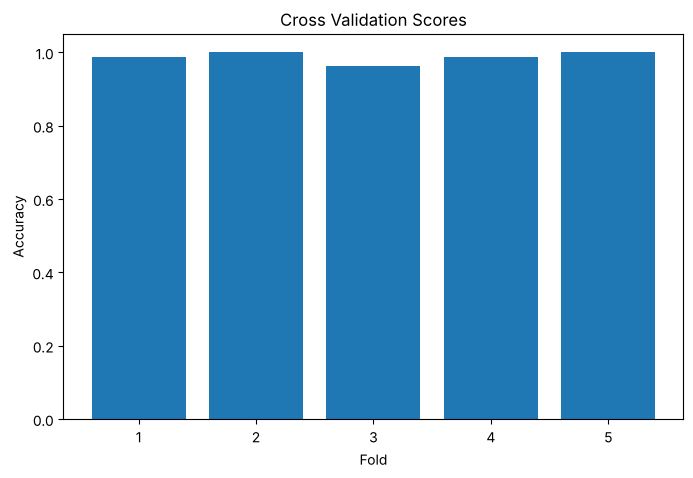

In [24]:
plt.figure(figsize=(8,5))

plt.bar(range(1,6), scores)

plt.title("Cross Validation Scores")
plt.xlabel("Fold")
plt.ylabel("Accuracy")

plt.show()

### Tumačenje grafikona 7

Rezultati pokazuju da Random Forest model ostvaruje veoma visoku tačnost u svim iteracijama unakrsne validacije.

Tačnost se kretala između 96,25% i 100%, dok je prosečna vrednost iznosila približno 98,75%.

Pošto su rezultati u svim iteracijama bili veoma slični, može se zaključiti da model daje stabilne rezultate i dobro se ponaša i na podacima koje ranije nije koristio.


# 7. Zaključak

U ovom projektu razvijen je model za predikciju hronične bolesti bubrega primenom metoda mašinskog učenja. Tokom rada izvršena je analiza i predobrada podataka, nakon čega su trenirana i upoređena tri modela: Logistic Regression, KNN i Random Forest.

Tokom predobrade pokazalo se da je pažljivo čišćenje podataka veoma važno. Pojedine numeričke kolone bile su učitane kao tekst, a kategoričke vrednosti su sadržale suvišne razmake. Nakon ispravljanja ovih problema podaci su verno predstavljali stvarne medicinske vrednosti pacijenata.

Rezultati su pokazali da su sva tri modela ostvarila visoku tačnost, pri čemu se Random Forest izdvojio kao najuspešniji. Na test skupu ostvario je tačnost od 100%, dok su logistička regresija i KNN sa skaliranim atributima postigli po 97,5%. Poređenje KNN modela sa i bez skaliranja (68,75% naspram 97,5%) pokazalo je koliko način pripreme podataka utiče na algoritme koji se zasnivaju na udaljenosti. Unakrsna validacija potvrdila je da Random Forest daje stabilne rezultate, sa prosečnom tačnošću od 98,75%.

Na osnovu dobijenih rezultata može se zaključiti da metode mašinskog učenja mogu uspešno da se primene za predikciju hronične bolesti bubrega i da predstavljaju korisnu podršku u analizi medicinskih podataka. Ipak, rezultate treba posmatrati u okviru korišćenog skupa podataka, pa bi budući rad mogao da obuhvati testiranje na većim i raznovrsnijim skupovima, kao i ispitivanje dodatnih algoritama i optimizaciju njihovih parametara.